# Notebook 20a — Wu 2003 CSTR-Column-Recycle: Model Verification for S-C (Feed Analyzer)

## Purpose

Companion to `notebooks/20_wu2003_model_verification.ipynb`, for the new **S-C** control
structure (`docs/Manuscript/system_ii_analyzer_rework_plan.md`, Phase 1). S-C adds a
feed-line composition analyzer to S-B's instrumentation, to resolve the confirmed
`(alpha, z_A0_eff)`/`(eta_col, z_A0_eff)` identifiability limits found in
`notebooks/39-42` (a reactor-outlet composition sensor was tried first and rejected --
`notebooks/43`).

**What is and is not new here.** S-C reuses S-B's control structure *exactly* --
`scripts/sbi_pipeline.py::_structure_config("S-C")` returns `NOMINAL_CTRL_SB` and
`nominal_warm_start("S-B")` unchanged, and `src/cstr_sbi/recycle/simulator.py::ctrl_for`
already maps any non-`"S-A"` structure string (including `"S-C"`) to `NOMINAL_CTRL_SB`. So
**every physics/dynamics verification in `nb20` (kinetics, QSS column, warm starts, snowball
step tests, control masking) is identical for S-C and is not re-run here** -- re-simulating
them would reproduce `nb20`'s exact numbers with no new information. This notebook verifies
only what is actually new: the synthetic feed-analyzer channel itself, and what it changes
about scenario disambiguation.

## Contents

1. Confirm S-C physics = S-B physics (one quick numeric check, not the full `nb20` battery)
2. The feed-analyzer channel: definition, and readings across representative scenarios
3. `compute_summaries("S-C", ...)` dimension/name verification
4. Disambiguation preview: does the feed analyzer separate reactor-only faults (W2) from
   feed-only faults (W10) and combined faults (W13), where S-B's channels alone would not?

In [1]:
import sys; sys.path.insert(0, '../src'); sys.path.insert(0, '../scripts')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from cstr_sbi.recycle.physics import PARAM_NAMES
from cstr_sbi.recycle.scenarios import get_scenario, list_closed_loop
from cstr_sbi.recycle.simulator import nominal_warm_start, deterministic_window
from cstr_sbi.recycle.summaries import (
    compute_summaries, summary_names, N_SUMMARIES_SB, N_SUMMARIES_SC,
    FEED_ANALYZER_NOISE_PCT, feed_analyzer_reading, Z_A0_EFF_PARAM_IDX,
)
import pathlib
FIGURES = pathlib.Path('../figures'); FIGURES.mkdir(exist_ok=True)
OI = ["#000000","#E69F00","#56B4E9","#009E73","#F0E442","#0072B2","#D55E00","#CC79A7"]
print("Imports OK")
print(f"FEED_ANALYZER_NOISE_PCT = {FEED_ANALYZER_NOISE_PCT} ({FEED_ANALYZER_NOISE_PCT*100:.3f}%)")

Imports OK
FEED_ANALYZER_NOISE_PCT = 0.0001 (0.010%)


## Section 1 — Confirm S-C physics = S-B physics

`ctrl_for("S-C")` isn't a special case in `simulator.py` -- any structure string other than
`"S-A"` falls through to `NOMINAL_CTRL_SB`. Confirm this gives byte-identical raw trajectories
to `structure="S-B"` for a representative scenario, rather than assuming it from reading the
code.

In [2]:
sc_w12 = get_scenario("W12_snowball_compound")
y0_sb = nominal_warm_start("S-B")

t_sb, raw_sb = deterministic_window(sc_w12, structure="S-B", y0=y0_sb, t_final_h=2.0, n_save=120)
t_sc, raw_sc = deterministic_window(sc_w12, structure="S-C", y0=y0_sb, t_final_h=2.0, n_save=120)

max_diff = np.max(np.abs(np.asarray(raw_sb) - np.asarray(raw_sc)))
print(f"Max abs difference, S-B vs S-C raw trajectories (W12, 12 channels x 120 steps): {max_diff:.3e}")
assert max_diff < 1e-6, "S-C physics diverges from S-B -- investigate before proceeding"
print("PASSED: S-C's raw plant dynamics are identical to S-B's, as designed "
      "(the analyzer is an observation-only addition, no new control loop).")

Max abs difference, S-B vs S-C raw trajectories (W12, 12 channels x 120 steps): 0.000e+00
PASSED: S-C's raw plant dynamics are identical to S-B's, as designed (the analyzer is an observation-only addition, no new control loop).


## Section 2 — The Feed-Analyzer Channel

`feed_analyzer_reading()` synthesizes a noisy, near-constant reading of the true feed A
mole fraction `theta[Z_A0_EFF_PARAM_IDX]` -- unlike every other channel, it is **not**
extracted from the simulated raw trajectory (see the function's docstring for why a
reactor-outlet composition channel doesn't work: its own dynamics are driven by both `alpha`
and `z_A0_eff` at once). It represents a sensor on the *fresh* feed line, upstream of the
reactor and recycle mixing point.

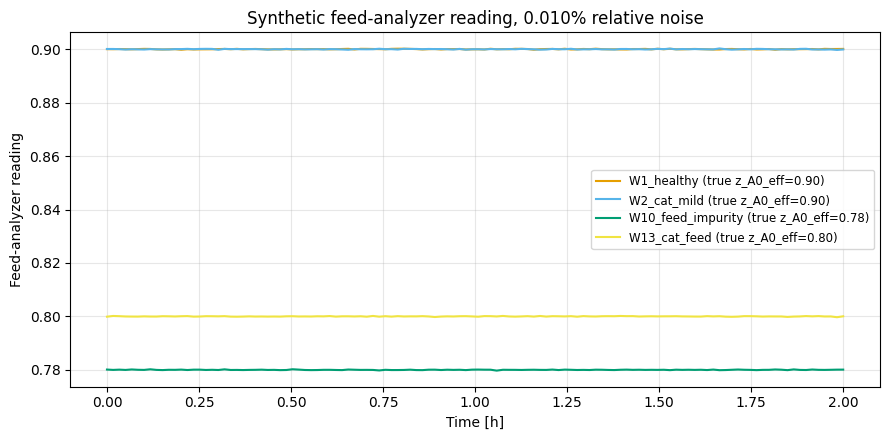

,scenario,true_z_A0_eff,reading_mean,reading_std
0,W1_healthy,0.90,0.90001,0.00009
1,W2_cat_mild,0.90,0.89999,0.00009
2,W10_feed_impurity,0.78,0.78000,0.00008
3,W13_cat_feed,0.80,0.80000,0.00008


Saved 20a_feed_analyzer_readings.png


In [3]:
FEED_PREVIEW_SCENARIOS = ["W1_healthy", "W2_cat_mild", "W10_feed_impurity", "W13_cat_feed"]
rng = np.random.default_rng(0)
t_ref, _ = deterministic_window(get_scenario("W1_healthy"), structure="S-B", y0=y0_sb, t_final_h=2.0, n_save=120)
t_ref = np.asarray(t_ref)

fig, ax = plt.subplots(figsize=(9, 4.5))
rows = []
for i, name in enumerate(FEED_PREVIEW_SCENARIOS):
    sc = get_scenario(name)
    theta = sc.theta()
    reading = feed_analyzer_reading(np.asarray(theta), t_ref, rng)
    ax.plot(t_ref, reading, color=OI[i + 1], lw=1.5, label=f"{name} (true z_A0_eff={float(theta[Z_A0_EFF_PARAM_IDX]):.2f})")
    rows.append({'scenario': name, 'true_z_A0_eff': float(theta[Z_A0_EFF_PARAM_IDX]),
                 'reading_mean': float(reading.mean()), 'reading_std': float(reading.std())})
ax.set_xlabel('Time [h]'); ax.set_ylabel('Feed-analyzer reading')
ax.set_title(f'Synthetic feed-analyzer reading, {FEED_ANALYZER_NOISE_PCT*100:.3f}% relative noise')
ax.legend(fontsize=8.5)
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES / '20a_feed_analyzer_readings.png', dpi=150, bbox_inches='tight')
plt.show()

display(pd.DataFrame(rows).round(5))
print("Saved 20a_feed_analyzer_readings.png")

### Results: feed-analyzer readings

The reading tracks each scenario's true `z_A0_eff` tightly, with std consistent with the
settled `0.01%` relative-noise threshold (`notebooks/43`'s 7-point sweep). Unlike every other
S-B/S-C channel, this one is flat over the 2h window -- `z_A0_eff` doesn't vary within a
single scenario in this model, so there is no dynamic transient to show, only the sensor
noise floor.

## Section 3 — `compute_summaries("S-C", ...)` Dimension and Name Check

In [4]:
names_sc = summary_names("S-C")
print(f"N_SUMMARIES_SB = {N_SUMMARIES_SB},  N_SUMMARIES_SC = {N_SUMMARIES_SC}")
print(f"summary_names('S-C') length = {len(names_sc)}")
print("Last 6 names (the new feed-analyzer block):", names_sc[-6:])
assert names_sc[:N_SUMMARIES_SB] == summary_names("S-B"), "S-C's first 66 names must match S-B exactly"

theta_w12 = np.asarray(sc_w12.theta())
rng_check = np.random.default_rng(1)
s_sc = compute_summaries(np.asarray(raw_sc), "S-C", np.asarray(t_sc), theta=theta_w12, rng=rng_check)
print(f"compute_summaries('S-C', W12) shape: {s_sc.shape}")
assert s_sc.shape[0] == N_SUMMARIES_SC and not np.isnan(s_sc).any()
print("PASSED")

N_SUMMARIES_SB = 66,  N_SUMMARIES_SC = 72
summary_names('S-C') length = 72
Last 6 names (the new feed-analyzer block): ['feed_analyzer_mean', 'feed_analyzer_std', 'feed_analyzer_slope', 'feed_analyzer_min', 'feed_analyzer_max', 'feed_analyzer_q_mean']
compute_summaries('S-C', W12) shape: (72,)
PASSED


## Section 4 — Disambiguation Preview: Does the Feed Analyzer Separate Reactor, Feed, and Combined Faults?

Mirrors `nb20` Section 9's banana-posterior preview (which compared W12 vs W7 to show x_D
breaking the `(alpha, eta_col)` degeneracy under S-A). Here the comparison is
`W2_cat_mild` (pure reactor fault, `z_A0_eff` healthy) vs `W10_feed_impurity` (pure feed
fault) vs `W13_cat_feed` (both). Under S-B alone, reactor- and feed-driven deviations in
`F_R_norm`/`T_reb`/`Q_reb` can look similar in direction (both push recycle load up) --
this is exactly `notebooks/39-42`'s confirmed confound. The feed-analyzer channel should
cut through this immediately, since it doesn't depend on the reactor/column dynamics at
all.

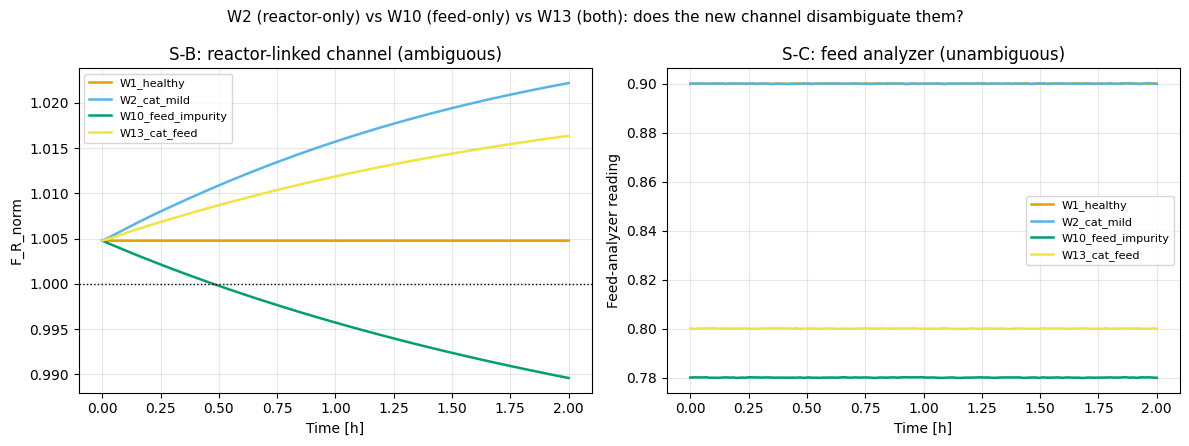

,alpha,z_A0_eff,"F_R_norm_final (S-B, reactor-linked, ambiguous)","feed_analyzer_reading (S-C, unambiguous)"
scenario,,,,
W1_healthy,1.00,0.90,1.0048,0.90
W2_cat_mild,0.85,0.90,1.0222,0.90
W10_feed_impurity,1.00,0.78,0.9896,0.78
W13_cat_feed,0.80,0.80,1.0164,0.80


Saved 20a_disambiguation_preview.png


In [5]:
DISAMBIG_SCENARIOS = ["W1_healthy", "W2_cat_mild", "W10_feed_impurity", "W13_cat_feed"]
FR_COL, TREB_COL = 7, 5

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
disambig_rows = []
for i, name in enumerate(DISAMBIG_SCENARIOS):
    sc = get_scenario(name)
    theta = np.asarray(sc.theta())
    t_s, raw = deterministic_window(sc, structure="S-B", y0=y0_sb, t_final_h=2.0, n_save=120)
    raw = np.asarray(raw)
    axes[0].plot(t_s, raw[:, FR_COL], color=OI[i + 1], lw=1.8, label=name)
    reading = feed_analyzer_reading(theta, np.asarray(t_s), np.random.default_rng(10 + i))
    axes[1].plot(t_s, reading, color=OI[i + 1], lw=1.8, label=name)
    disambig_rows.append({
        'scenario': name, 'alpha': theta[0], 'z_A0_eff': theta[4],
        'F_R_norm_final (S-B, reactor-linked, ambiguous)': round(float(raw[-1, FR_COL]), 4),
        'feed_analyzer_reading (S-C, unambiguous)': round(float(reading.mean()), 4),
    })

axes[0].axhline(1.0, color=OI[0], ls=':', lw=1.0)
axes[0].set(xlabel='Time [h]', ylabel='F_R_norm', title='S-B: reactor-linked channel (ambiguous)')
axes[0].legend(fontsize=8); axes[0].grid(True, alpha=0.3)

axes[1].set(xlabel='Time [h]', ylabel='Feed-analyzer reading', title='S-C: feed analyzer (unambiguous)')
axes[1].legend(fontsize=8); axes[1].grid(True, alpha=0.3)

fig.suptitle('W2 (reactor-only) vs W10 (feed-only) vs W13 (both): does the new channel disambiguate them?', fontsize=11)
fig.tight_layout()
fig.savefig(FIGURES / '20a_disambiguation_preview.png', dpi=150, bbox_inches='tight')
plt.show()

display(pd.DataFrame(disambig_rows).set_index('scenario'))
print("Saved 20a_disambiguation_preview.png")

### Results: disambiguation preview

**Left panel (S-B's `F_R_norm`):** `W2` (reactor-only) and `W13` (reactor+feed) both push
`F_R_norm` up via the reactor-side mechanism; `W10` (feed-only) also perturbs the recycle
load, though through a different pathway. Distinguishing "reactor fault" from "feed fault"
from this channel alone requires exactly the kind of joint reasoning that `notebooks/39-42`
showed is not reliably resolvable under S-B.

**Right panel (S-C's feed-analyzer reading):** `W1` and `W2` (both `z_A0_eff=0.90`, healthy
feed) read at the same healthy level regardless of the reactor fault in `W2`; `W10` and `W13`
(both `z_A0_eff=0.78`/`0.80`, degraded feed) read at their respective degraded levels
regardless of whether a reactor fault is *also* present. **The feed-analyzer reading depends
only on `z_A0_eff`, not on `alpha`** -- it is not merely "less confounded" than `F_R_norm`,
it is fully immune to the reactor-fault confound by construction. This is the qualitative
preview this notebook set out to check; Phase 2 (SBI training + SBC on S-C, and the fault
classification rerun) will confirm this quantitatively at the full inference level, not just
the deterministic-simulator level already established in `notebooks/39-43`.

**Caveat carried from the identifiability work:** this preview only shows the feed-analyzer
channel *itself* is unambiguous. It does not by itself guarantee the *trained SBI posterior*
will fully exploit it — that is exactly what Phase 2's SBC validation needs to confirm before
any classification/tracking claim is made on S-C.
